# LAB2 - Bài 4 (Trang 26): Red Wine Quality

Đinh Nhật Huyền Nhân - 6451071055 - CQ.64.CNTT

### Chuẩn bị thư viện và dữ liệu

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

In [2]:
print("Đinh Nhật Huyền Nhân - 6451071055")
data = pd.read_csv('data/winequality-red.csv')
print('Kích thước dữ liệu:', data.shape)
print('Số ô dữ liệu trống:', data.isna().sum().sum())
print('Số dòng trùng lặp:', data.duplicated().sum())
data.head()

Đinh Nhật Huyền Nhân - 6451071055
Kích thước dữ liệu: (1599, 12)
Số ô dữ liệu trống: 0
Số dòng trùng lặp: 240


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


### Câu 3: Khảo sát độ tương đồng giữa các cột bằng công thức Pearson

Đinh Nhật Huyền Nhân - 6451071055


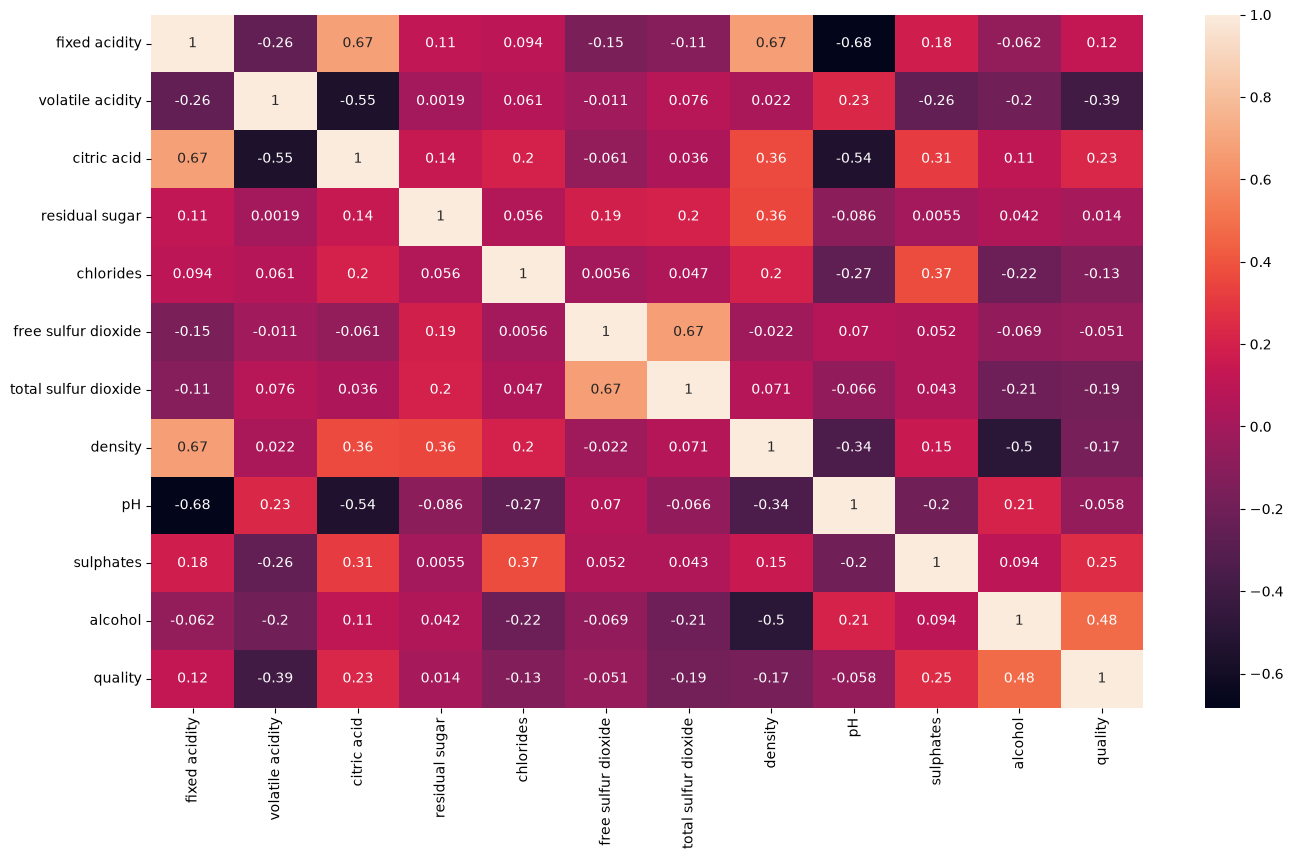

Các cặp có |r| >= 0.8: không có
Cặp tương quan mạnh nhất: fixed acidity - pH = -0.683


In [3]:
print("Đinh Nhật Huyền Nhân - 6451071055")
corr = data.corr(method='pearson', numeric_only=True)
plt.figure(figsize=(16, 9))
sns.heatmap(corr, annot=True)
plt.show()

# Liệt kê các cặp thuộc tính có |r| >= 0.8 (không xét thuộc tính quyết định)
threshold = 0.8
pairs = corr.drop(columns='quality', errors='ignore').drop(index='quality', errors='ignore')
high_corr = [(a, b, round(pairs.loc[a, b], 3))
             for i, a in enumerate(pairs.columns)
             for b in pairs.columns[i + 1:]
             if abs(pairs.loc[a, b]) >= threshold]
print('Các cặp có |r| >= 0.8:', high_corr if high_corr else 'không có')

# Cặp tương quan mạnh nhất để đối chiếu với ngưỡng
strongest = max(((a, b, pairs.loc[a, b])
                 for i, a in enumerate(pairs.columns)
                 for b in pairs.columns[i + 1:]), key=lambda t: abs(t[2]))
print('Cặp tương quan mạnh nhất:', strongest[0], '-', strongest[1], '=', round(strongest[2], 3))

**Nhận xét:** Không có cặp thuộc tính nào có |r| ≥ 0,8. Cặp tương quan mạnh nhất là fixed acidity và pH với r = -0,683, chưa đến mức cao nên giữ lại toàn bộ các cột.

### Câu 4: Tách thuộc tính bình thường và thuộc tính quyết định

In [4]:
print("Đinh Nhật Huyền Nhân - 6451071055")
features = data.drop('quality', axis=1)
labels = data['quality']
print('features:', features.shape)
print('labels:', labels.shape)
print(labels.value_counts().sort_index().to_string())

Đinh Nhật Huyền Nhân - 6451071055
features: (1599, 11)
labels: (1599,)
quality
3     10
4     53
5    681
6    638
7    199
8     18


### Câu 5: Chuyển các cột không phải dạng số về one-hot vector

In [5]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Chỉ lấy cột không phải dạng số: np.number bao gồm cả int64 và float64
non_numeric = features.select_dtypes(exclude=[np.number]).columns
print('Các cột không phải dạng số:', list(non_numeric))
features_onehot = pd.get_dummies(features, columns=non_numeric, dtype=int)
print('Kích thước sau khi chuyển đổi:', features_onehot.shape)
features_onehot.head()

Đinh Nhật Huyền Nhân - 6451071055
Các cột không phải dạng số: []
Kích thước sau khi chuyển đổi: (1599, 11)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4


**Nhận xét:** Tất cả các cột đều là dạng số nên không có cột nào cần chuyển đổi, số cột giữ nguyên là 11. Câu lệnh `exclude=['int64']` trong tài liệu sẽ chọn nhầm các cột float64 của dữ liệu này, vì vậy bài dùng `np.number`.

### Câu 6: Tách dữ liệu huấn luyện và kiểm thử

In [6]:
print("Đinh Nhật Huyền Nhân - 6451071055")
X = features_onehot
y = labels
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print('Number of training data:', len(X_train))
print('Number of test data:', len(X_test))

Đinh Nhật Huyền Nhân - 6451071055
Number of training data: 1119
Number of test data: 480


**Nhận xét:** Chia theo đúng câu lệnh trong đề: 1119 mẫu huấn luyện (70%) và 480 mẫu kiểm thử (30%).

### Câu 7: Xây dựng cây ID3 và kiểm thử bằng ma trận nhầm lẫn

In [7]:
print("Đinh Nhật Huyền Nhân - 6451071055")
id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
# Train Decision Tree Classifier
id3.fit(X_train, y_train)
print('Độ sâu của cây:', id3.get_depth(), '- Số nút lá:', id3.get_n_leaves())

Đinh Nhật Huyền Nhân - 6451071055
Độ sâu của cây: 18 - Số nút lá: 273


In [8]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Predict the response for test dataset
id3_pred = id3.predict(X_test)

# Model Accuracy, how often is the classifier correct?
id3_score = metrics.accuracy_score(y_test, id3_pred)
print("Accuracy:", id3_score)
print("Report:", metrics.classification_report(y_test, id3_pred, zero_division=0))

Đinh Nhật Huyền Nhân - 6451071055
Accuracy: 0.5833333333333334
Report:               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.08      0.12      0.10        17
           5       0.70      0.66      0.68       195
           6       0.60      0.60      0.60       200
           7       0.43      0.46      0.44        61
           8       0.25      0.17      0.20         6

    accuracy                           0.58       480
   macro avg       0.34      0.33      0.34       480
weighted avg       0.59      0.58      0.59       480



Đinh Nhật Huyền Nhân - 6451071055
[[  0   1   0   0   0   0]
 [  0   2   8   7   0   0]
 [  2  14 129  43   7   0]
 [  0   7  44 120  28   1]
 [  0   0   3  28  28   2]
 [  0   0   1   2   2   1]]


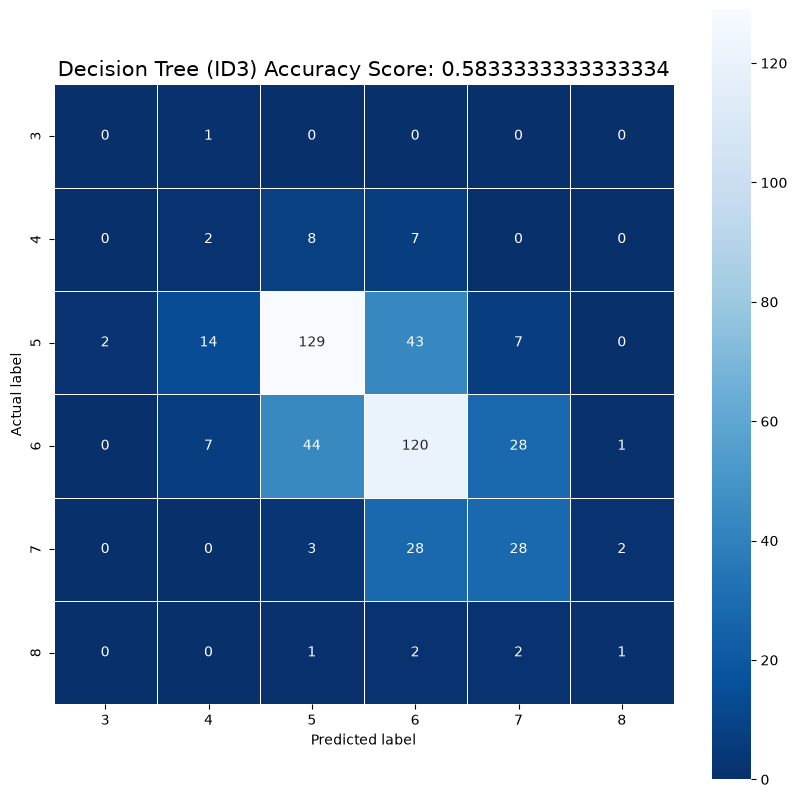

In [9]:
print("Đinh Nhật Huyền Nhân - 6451071055")
id3_cm = metrics.confusion_matrix(y_test, id3_pred, labels=id3.classes_)
print(id3_cm)

plt.figure(figsize=(10, 10))
sns.heatmap(id3_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Blues_r',
            xticklabels=id3.classes_, yticklabels=id3.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title('Decision Tree (ID3) Accuracy Score: {0}'.format(id3_score), size=15)
plt.show()

Đinh Nhật Huyền Nhân - 6451071055


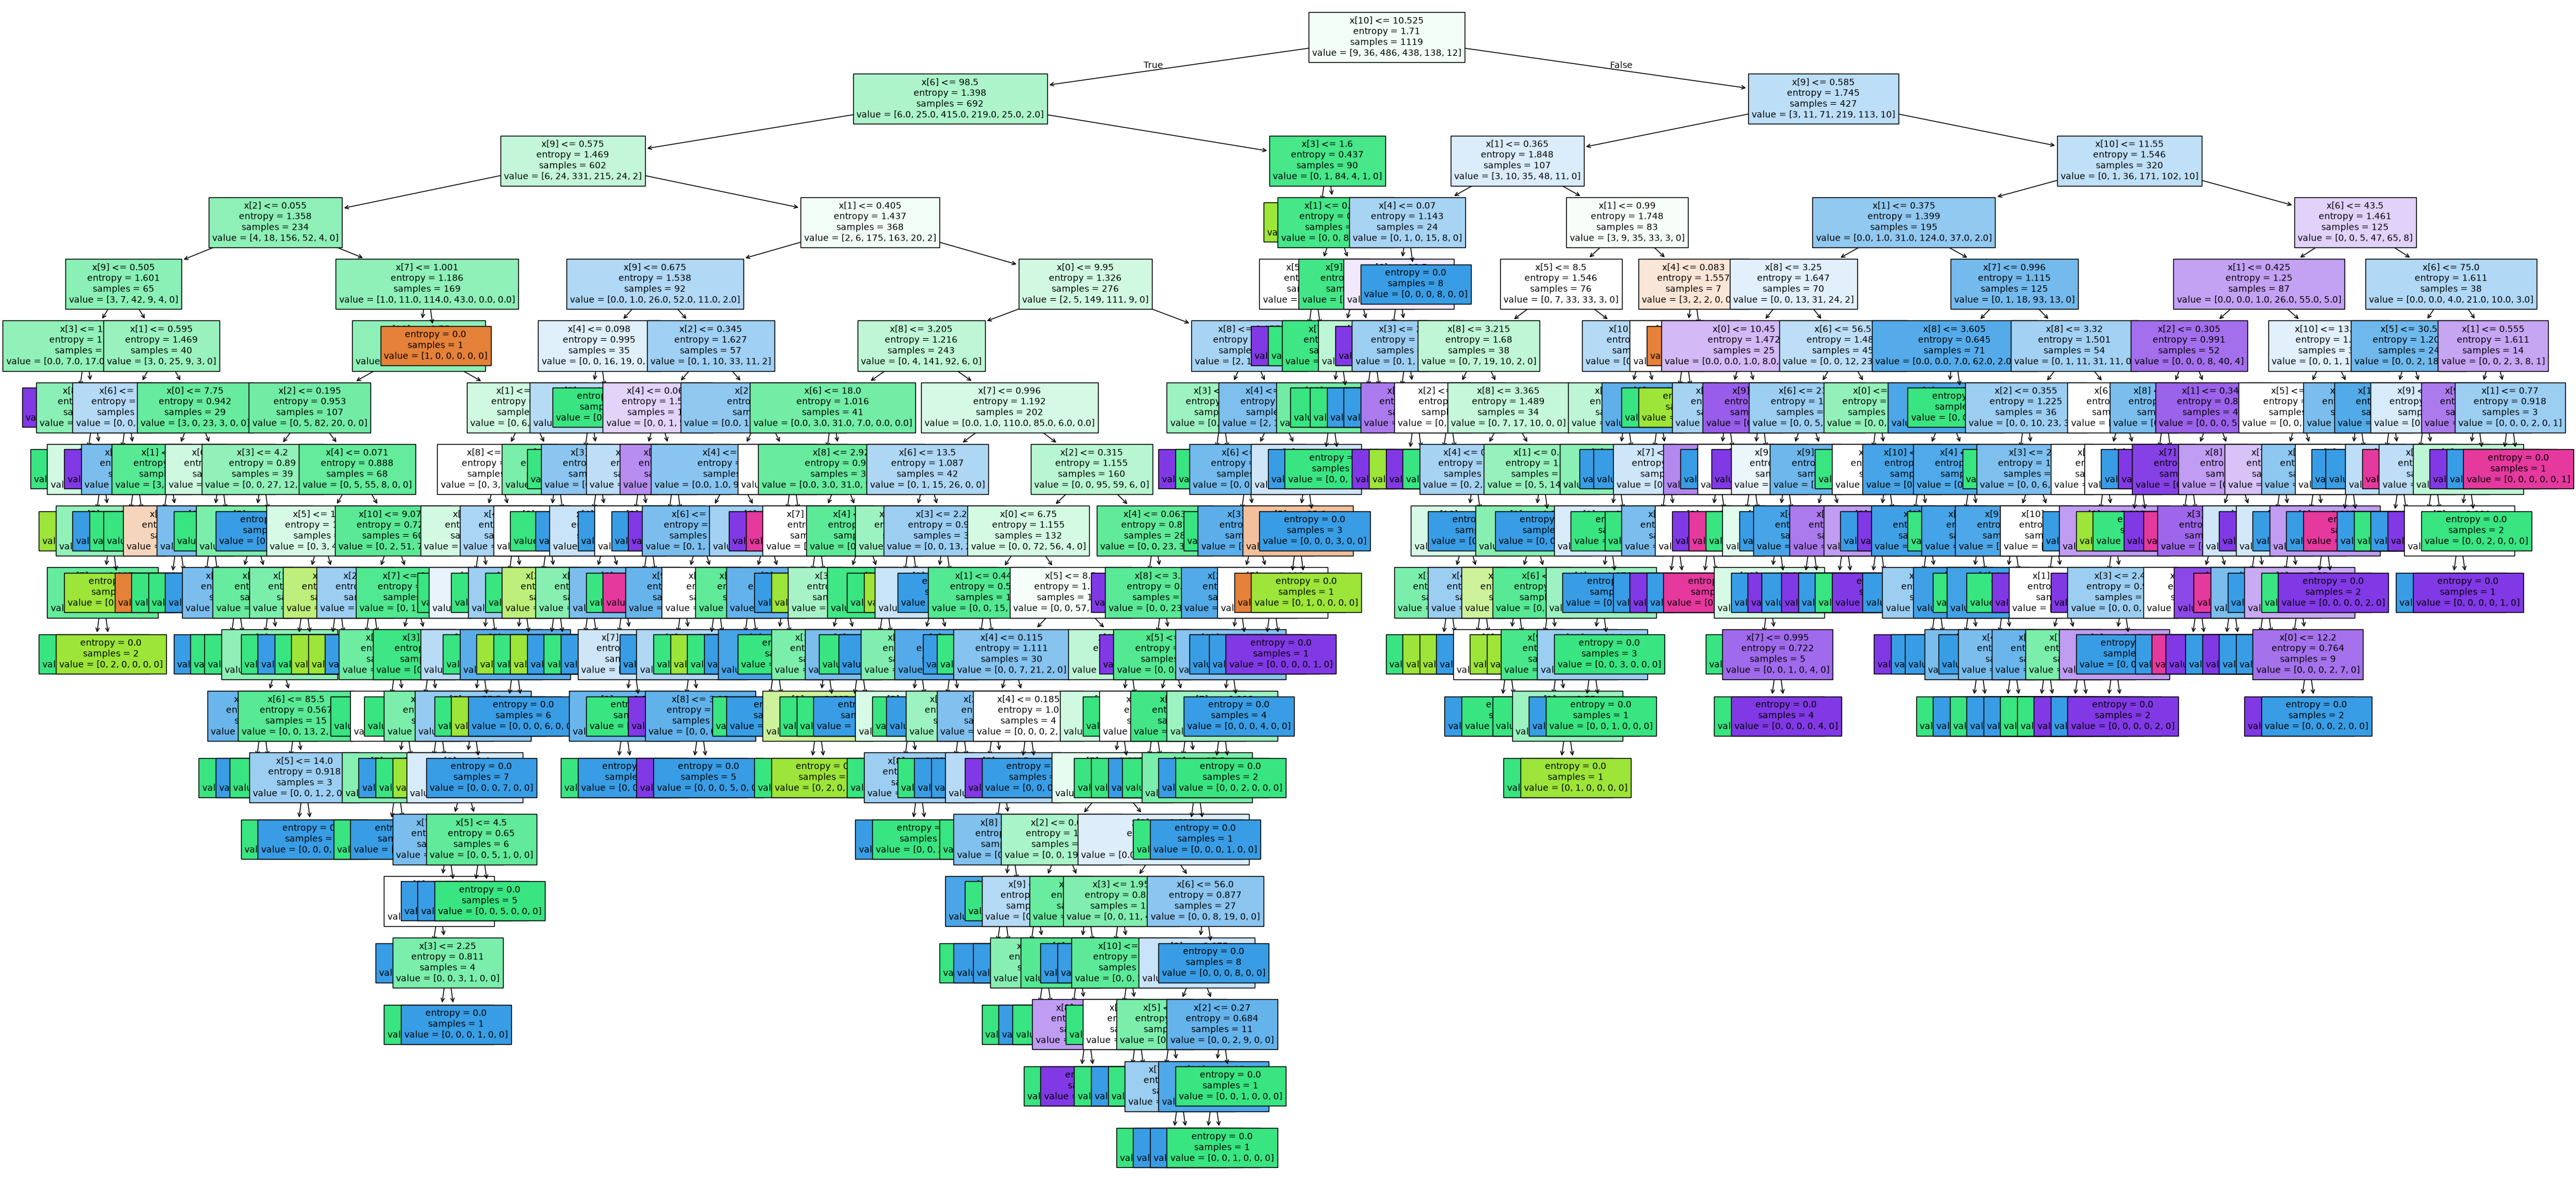

In [10]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Biểu diễn toàn bộ cây và lưu vào file ảnh
fig, ax = plt.subplots(figsize=(50, 24))
tree.plot_tree(id3, filled=True, fontsize=10)
plt.savefig('outputs/bai4_id3_tree', dpi=100)
plt.show()

Đinh Nhật Huyền Nhân - 6451071055


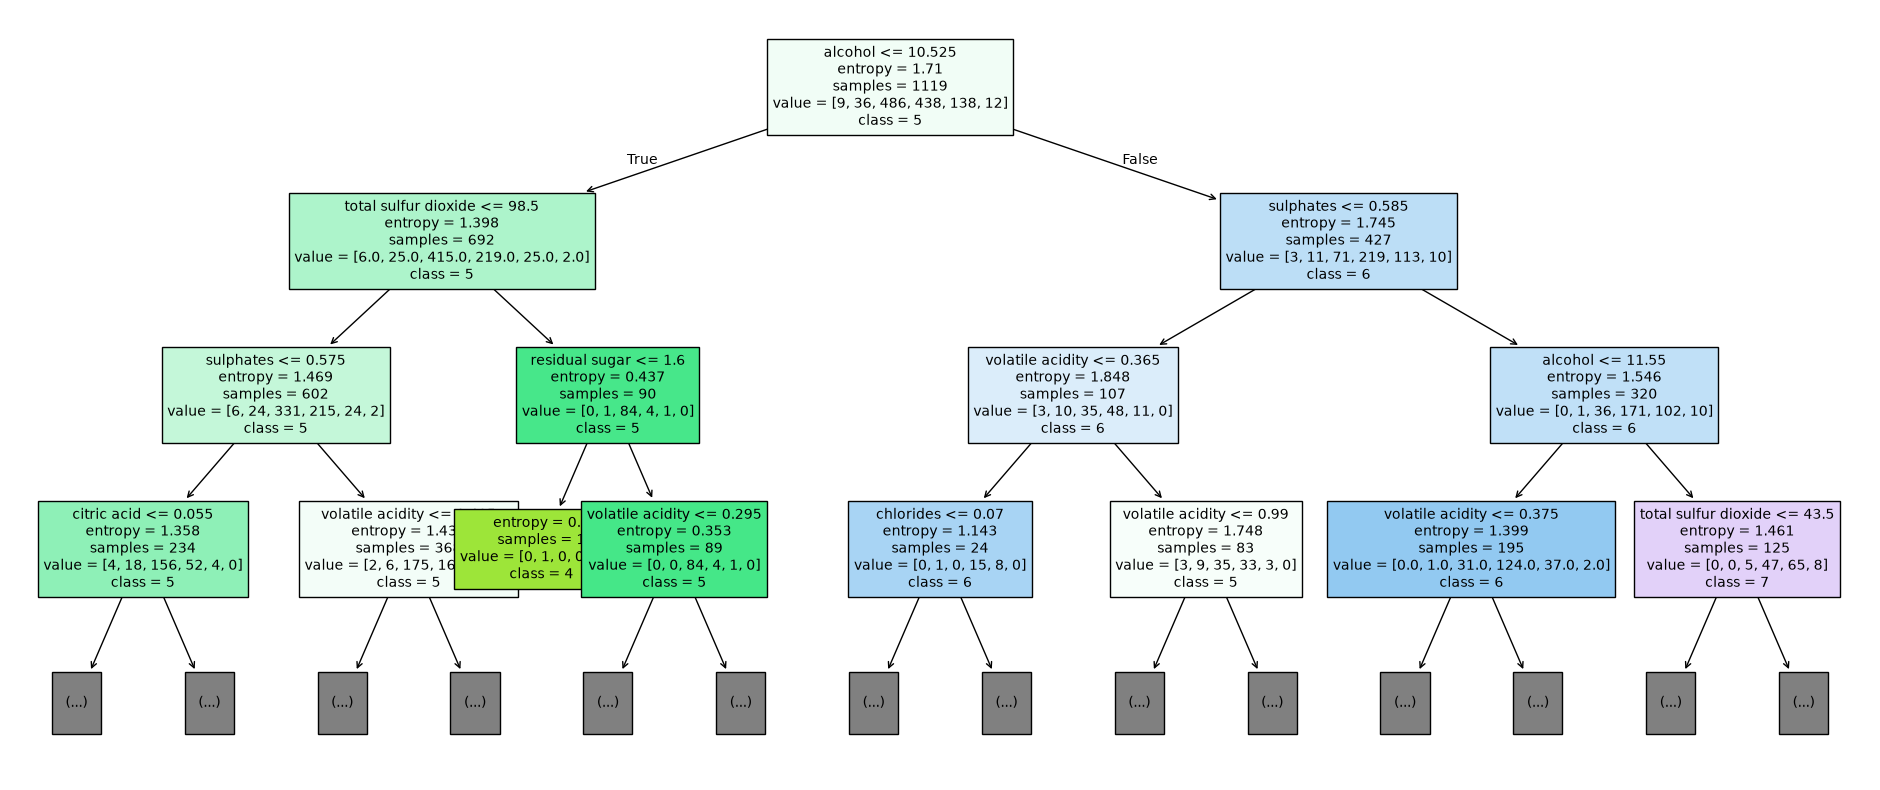

In [11]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Cây đầy đủ rất lớn nên vẽ thêm 3 tầng đầu với tên thuộc tính để dễ đọc
fig, ax = plt.subplots(figsize=(24, 10))
tree.plot_tree(id3, max_depth=3, feature_names=list(X_train.columns),
               class_names=[str(c) for c in id3.classes_], filled=True, fontsize=10)
plt.savefig('outputs/bai4_id3_tree_top3', dpi=100)
plt.show()

### Câu 8: Xây dựng cây CART (criterion='gini')

In [12]:
print("Đinh Nhật Huyền Nhân - 6451071055")
cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
# Train Decision Tree Classifier
cart.fit(X_train, y_train)
print('Độ sâu của cây:', cart.get_depth(), '- Số nút lá:', cart.get_n_leaves())

Đinh Nhật Huyền Nhân - 6451071055
Độ sâu của cây: 19 - Số nút lá: 287


In [13]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Predict the response for test dataset
cart_pred = cart.predict(X_test)

# Model Accuracy, how often is the classifier correct?
cart_score = metrics.accuracy_score(y_test, cart_pred)
print("Accuracy:", cart_score)
print("Report:", metrics.classification_report(y_test, cart_pred, zero_division=0))

Đinh Nhật Huyền Nhân - 6451071055
Accuracy: 0.5625
Report:               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.07      0.06      0.06        17
           5       0.64      0.62      0.63       195
           6       0.57      0.58      0.57       200
           7       0.45      0.49      0.47        61
           8       0.33      0.33      0.33         6

    accuracy                           0.56       480
   macro avg       0.34      0.35      0.35       480
weighted avg       0.56      0.56      0.56       480



Đinh Nhật Huyền Nhân - 6451071055
[[  0   0   1   0   0   0]
 [  0   1  11   4   1   0]
 [  1   9 121  59   4   1]
 [  0   3  50 116  30   1]
 [  0   1   5  23  30   2]
 [  0   0   0   2   2   2]]


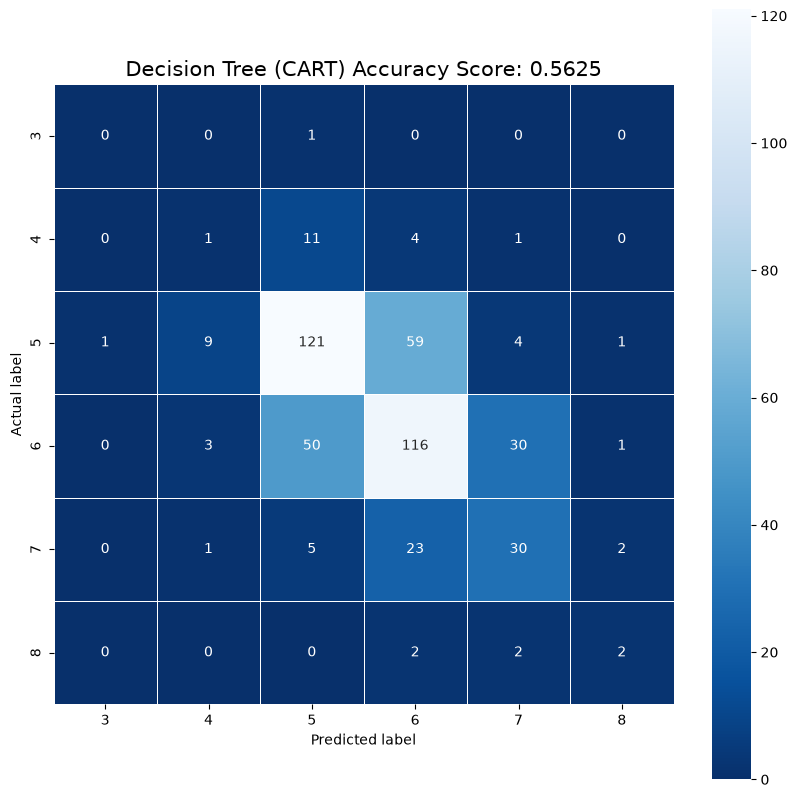

In [14]:
print("Đinh Nhật Huyền Nhân - 6451071055")
cart_cm = metrics.confusion_matrix(y_test, cart_pred, labels=cart.classes_)
print(cart_cm)

plt.figure(figsize=(10, 10))
sns.heatmap(cart_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Blues_r',
            xticklabels=cart.classes_, yticklabels=cart.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title('Decision Tree (CART) Accuracy Score: {0}'.format(cart_score), size=15)
plt.show()

Đinh Nhật Huyền Nhân - 6451071055


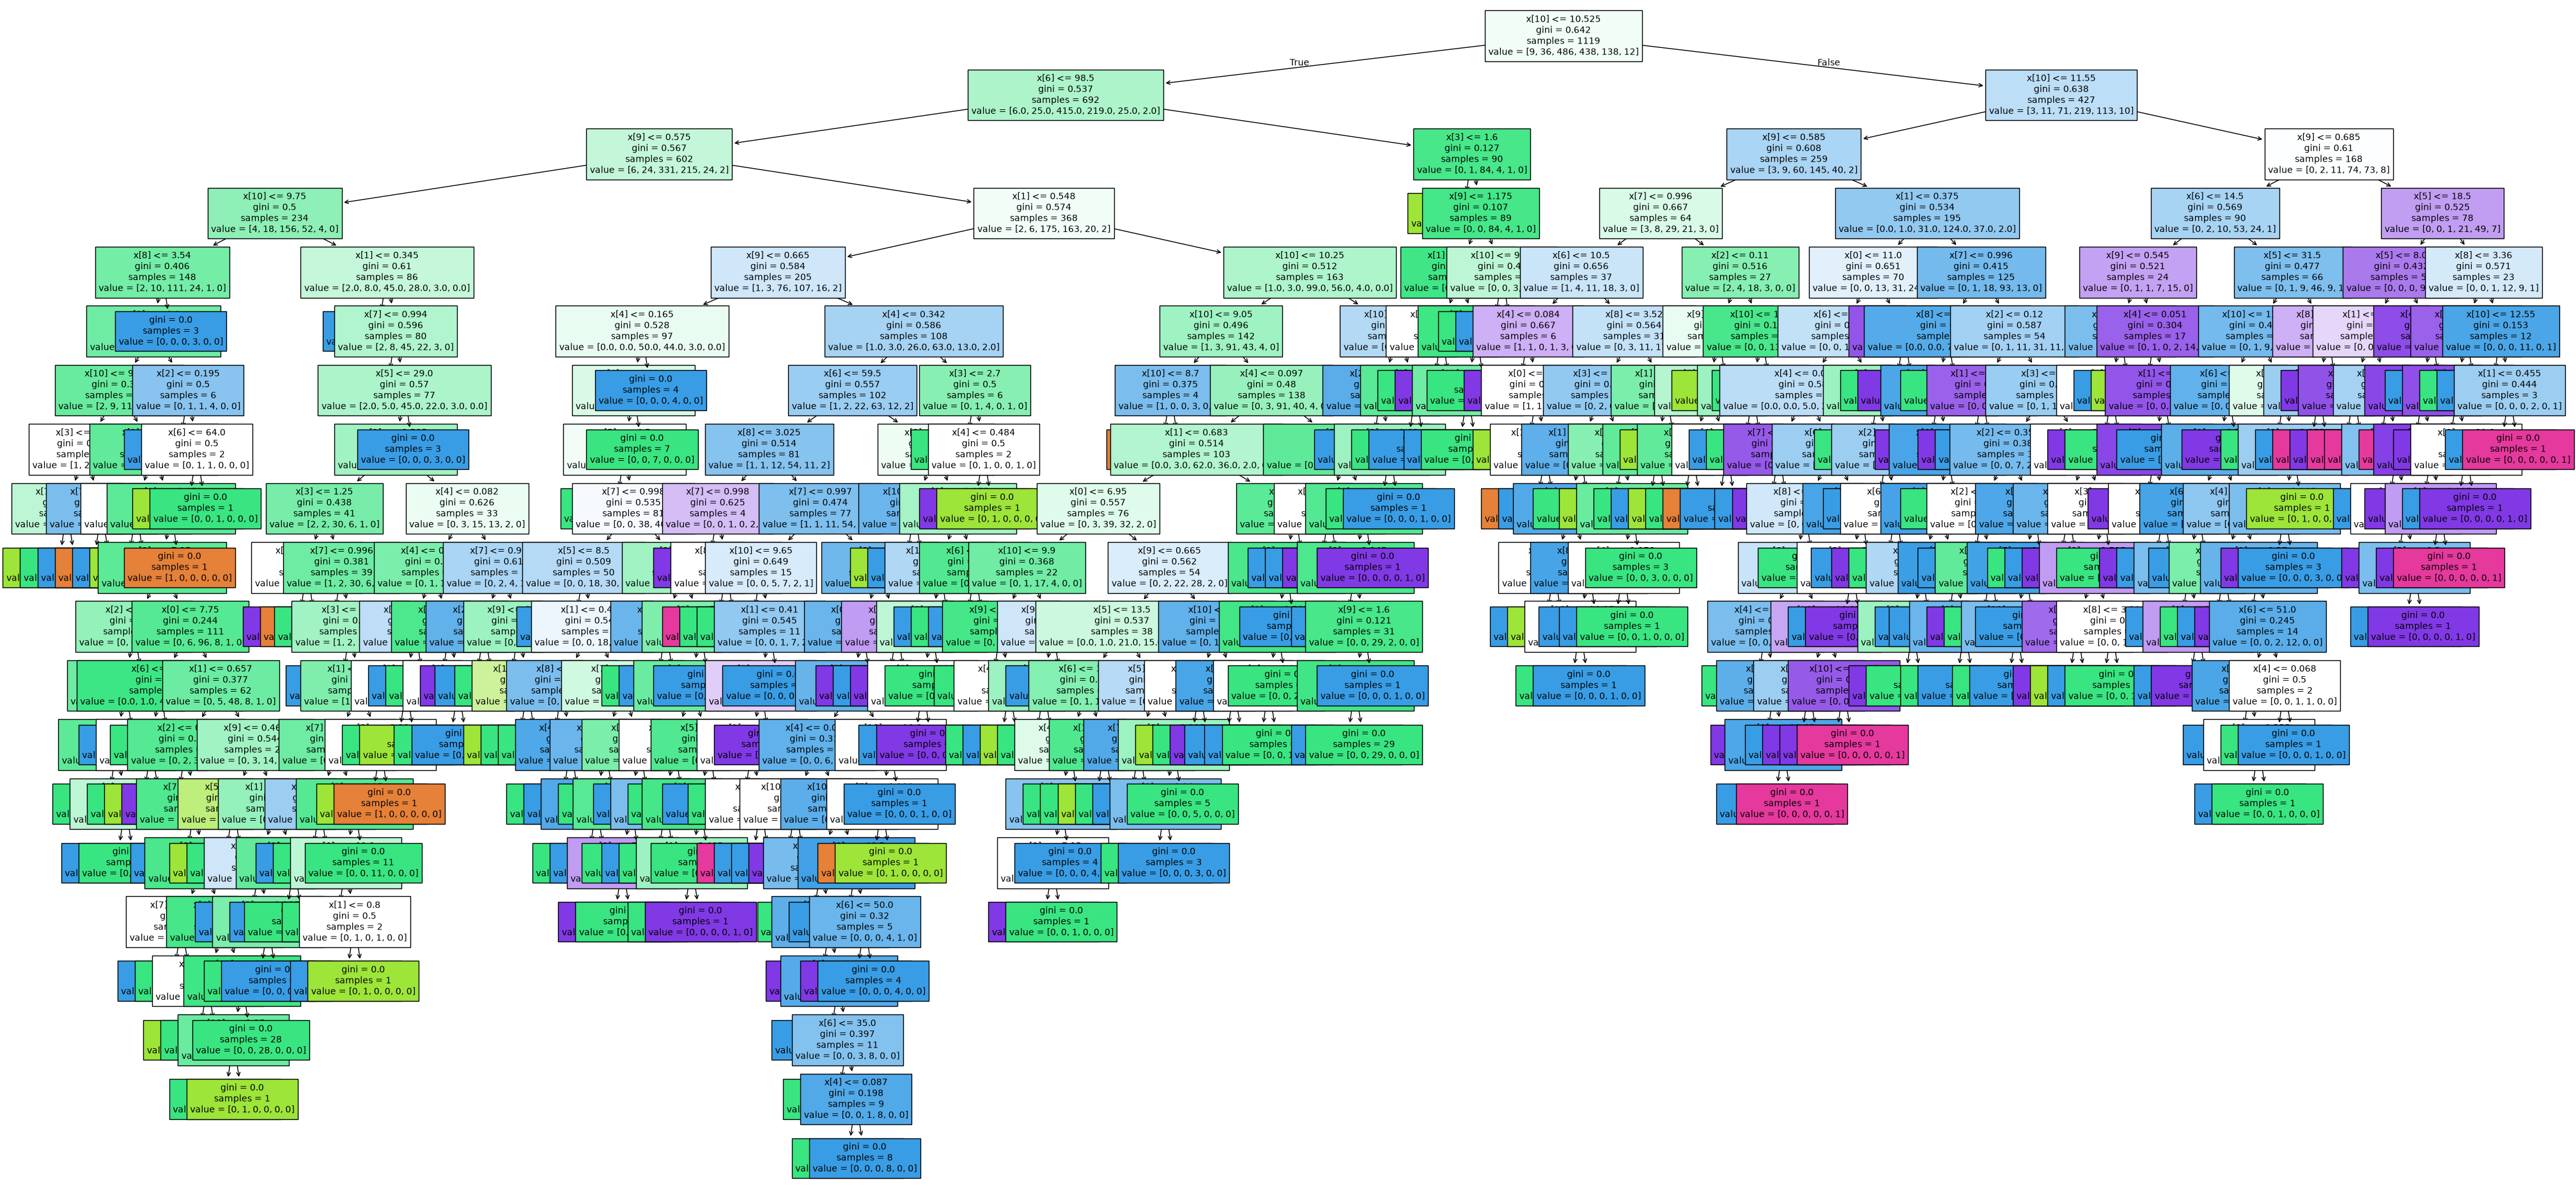

In [15]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Biểu diễn toàn bộ cây và lưu vào file ảnh
fig, ax = plt.subplots(figsize=(50, 24))
tree.plot_tree(cart, filled=True, fontsize=10)
plt.savefig('outputs/bai4_cart_tree', dpi=100)
plt.show()

Đinh Nhật Huyền Nhân - 6451071055


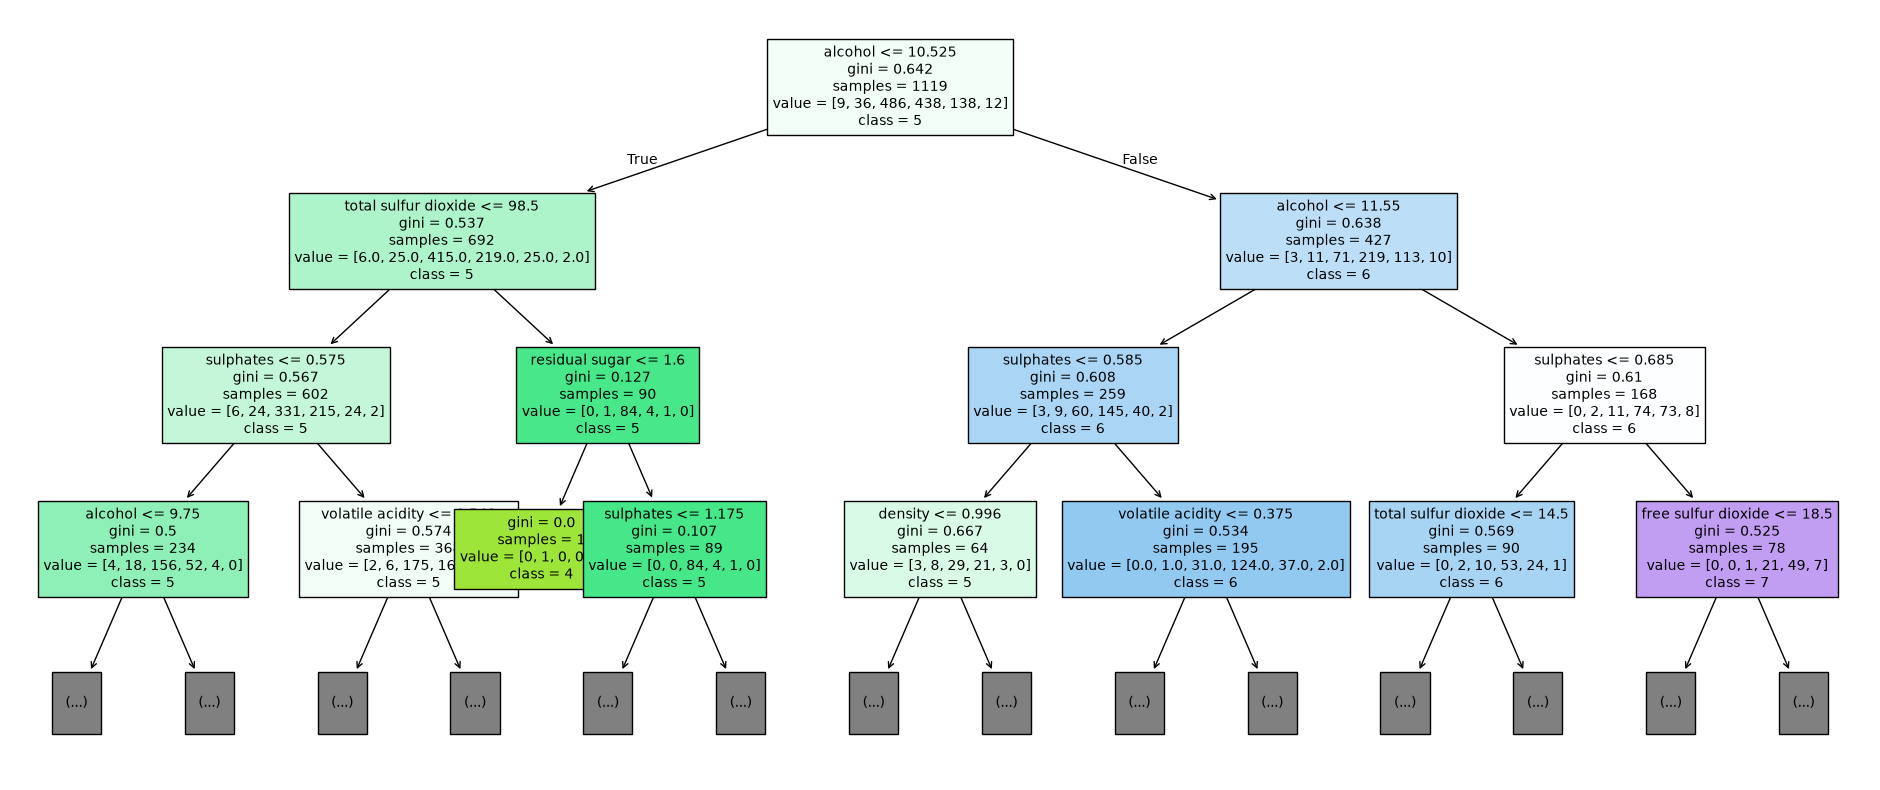

In [16]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Cây đầy đủ rất lớn nên vẽ thêm 3 tầng đầu với tên thuộc tính để dễ đọc
fig, ax = plt.subplots(figsize=(24, 10))
tree.plot_tree(cart, max_depth=3, feature_names=list(X_train.columns),
               class_names=[str(c) for c in cart.classes_], filled=True, fontsize=10)
plt.savefig('outputs/bai4_cart_tree_top3', dpi=100)
plt.show()

### Câu 9: Xây dựng mô hình Naïve Bayes

In [17]:
print("Đinh Nhật Huyền Nhân - 6451071055")
gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)

Đinh Nhật Huyền Nhân - 6451071055


In [18]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Model Accuracy, how often is the classifier correct?
bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print("Accuracy:", bayes_score)
print("Report:", metrics.classification_report(y_test, bayes_pred, zero_division=0))

Đinh Nhật Huyền Nhân - 6451071055
Accuracy: 0.5416666666666666
Report:               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.12      0.12      0.12        17
           5       0.68      0.62      0.65       195
           6       0.52      0.54      0.53       200
           7       0.40      0.49      0.44        61
           8       0.00      0.00      0.00         6

    accuracy                           0.54       480
   macro avg       0.29      0.29      0.29       480
weighted avg       0.55      0.54      0.54       480



Đinh Nhật Huyền Nhân - 6451071055
[[  0   0   1   0   0   0]
 [  1   2   8   6   0   0]
 [  0   6 121  63   5   0]
 [  0   9  46 107  35   3]
 [  0   0   3  28  30   0]
 [  0   0   0   1   5   0]]


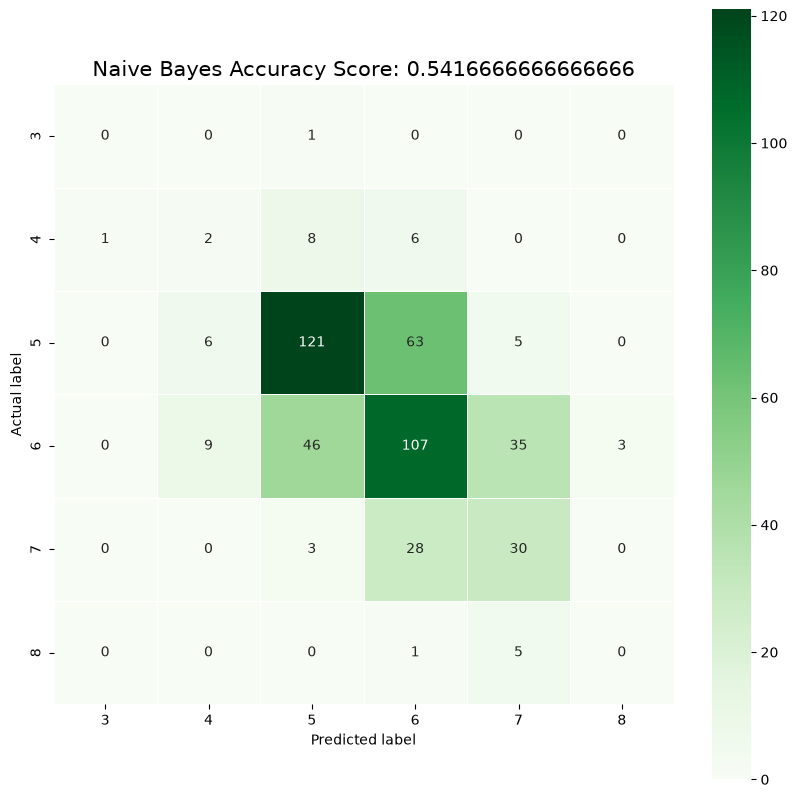

In [19]:
print("Đinh Nhật Huyền Nhân - 6451071055")
bayes_cm = metrics.confusion_matrix(y_test, bayes_pred, labels=gnb.classes_)
print(bayes_cm)

plt.figure(figsize=(10, 10))
sns.heatmap(bayes_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Greens',
            xticklabels=gnb.classes_, yticklabels=gnb.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title('Naive Bayes Accuracy Score: {0}'.format(bayes_score), size=15)
plt.show()

### Câu 10: So sánh kết quả của các mô hình

In [20]:
print("Đinh Nhật Huyền Nhân - 6451071055")
models = {'ID3': (id3, id3_pred), 'CART': (cart, cart_pred), 'Naive Bayes': (gnb, bayes_pred)}
rows = []
for name, (model, pred) in models.items():
    report = metrics.classification_report(y_test, pred, output_dict=True, zero_division=0)
    rows.append({'Model': name,
                 'Train acc': model.score(X_train, y_train),
                 'Test acc': report['accuracy'],
                 'Macro P': report['macro avg']['precision'],
                 'Macro R': report['macro avg']['recall'],
                 'Macro F1': report['macro avg']['f1-score'],
                 'Weighted F1': report['weighted avg']['f1-score']})
print(pd.DataFrame(rows).set_index('Model').round(4).to_string())

classes = sorted(y_test.unique())
print('\nĐộ chính xác (precision) theo từng lớp:')
print(pd.DataFrame({name: metrics.precision_score(y_test, pred, labels=classes, average=None, zero_division=0)
                    for name, (_, pred) in models.items()}, index=classes).round(4).to_string())
print('\nĐộ phủ (recall) theo từng lớp:')
print(pd.DataFrame({name: metrics.recall_score(y_test, pred, labels=classes, average=None, zero_division=0)
                    for name, (_, pred) in models.items()}, index=classes).round(4).to_string())

Đinh Nhật Huyền Nhân - 6451071055
             Train acc  Test acc  Macro P  Macro R  Macro F1  Weighted F1
Model                                                                    
ID3             1.0000    0.5833   0.3436   0.3341    0.3368       0.5883
CART            1.0000    0.5625   0.3441   0.3474    0.3455       0.5620
Naive Bayes     0.5737    0.5417   0.2859   0.2942    0.2890       0.5433

Độ chính xác (precision) theo từng lớp:
      ID3    CART  Naive Bayes
3  0.0000  0.0000       0.0000
4  0.0833  0.0714       0.1176
5  0.6973  0.6436       0.6760
6  0.6000  0.5686       0.5220
7  0.4308  0.4478       0.4000
8  0.2500  0.3333       0.0000

Độ phủ (recall) theo từng lớp:
      ID3    CART  Naive Bayes
3  0.0000  0.0000       0.0000
4  0.1176  0.0588       0.1176
5  0.6615  0.6205       0.6205
6  0.6000  0.5800       0.5350
7  0.4590  0.4918       0.4918
8  0.1667  0.3333       0.0000


**Nhận xét:** ID3 có accuracy kiểm thử cao nhất (0,5833), tiếp theo là CART (0,5625) và Naïve Bayes (0,5417). Xét Macro F1 thì CART nhỉnh hơn ID3 một chút (0,3455 so với 0,3368), Naïve Bayes thấp nhất (0,2890). Hai cây đạt accuracy 1,0 trên tập huấn luyện nhưng dưới 0,6 trên tập kiểm thử nên bị quá khớp rõ rệt; Naïve Bayes không quá khớp (0,5737 và 0,5417) nhưng mô hình chưa đủ tốt. Macro F1 thấp do dữ liệu lệch lớp: lớp 5 và 6 chiếm đa số, trong khi cả ba mô hình đều gần như không nhận đúng các lớp hiếm 3, 4 và 8 (lớp 3 chỉ có 1 mẫu kiểm thử). Dữ liệu có 240 dòng trùng lặp, không bị xóa vì đề không yêu cầu, nên có thể rơi vào cả hai tập và làm kết quả kiểm thử cao hơn thực tế.